In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import os

In [90]:
dataset_dir = Path("../data/bluebook-for-bulldozers")
if not (dataset_dir.is_dir()):
    print(f"[INFO] Can't find existing 'bluebook-for-bulldozers' dataset in current directory or parent directory, downloading...")

    # Download and unzip the bluebook for bulldozers dataset
    !wget https://github.com/mrdbourke/zero-to-mastery-ml/raw/refs/heads/master/data/bluebook-for-bulldozers.zip
    !unzip bluebook-for-bulldozers.zip

    # Ensure a data directory exists and move the downloaded dataset there
    !mkdir ../data/
    !mv bluebook-for-bulldozers ../data/
    print(f"[INFO] Current dataset dir: {dataset_dir}")

    # Remove .zip file from notebook directory
    !rm -rf bluebook-for-bulldozers.zip
else:
    # If the target dataset directory exists, we don't need to download it
    print(f"[INFO] 'bluebook-for-bulldozers' dataset exists, feel free to proceed!")
    print(f"[INFO] Current dataset dir: {dataset_dir}")

[INFO] 'bluebook-for-bulldozers' dataset exists, feel free to proceed!
[INFO] Current dataset dir: ../data/bluebook-for-bulldozers


In [91]:
from pathlib import Path

# Check if 'bluebook-for-bulldozers' exists in the current or parent directory
# Link to data (see the file "bluebook-for-bulldozers"): https://github.com/mrdbourke/zero-to-mastery-ml/tree/master/data
dataset_dir = Path("../data/bluebook-for-bulldozers")
if not (dataset_dir.is_dir()):
    print(f"[INFO] Can't find existing 'bluebook-for-bulldozers' dataset in current directory or parent directory, downloading...")

    # Download and unzip the bluebook for bulldozers dataset
    !wget https://github.com/mrdbourke/zero-to-mastery-ml/raw/refs/heads/master/data/bluebook-for-bulldozers.zip
    !unzip bluebook-for-bulldozers.zip

    # Ensure a data directory exists and move the downloaded dataset there
    !mkdir ../data/
    !mv bluebook-for-bulldozers ../data/
    print(f"[INFO] Current dataset dir: {dataset_dir}")

    # Remove .zip file from notebook directory
    !rm -rf bluebook-for-bulldozers.zip
else:
    # If the target dataset directory exists, we don't need to download it
    print(f"[INFO] 'bluebook-for-bulldozers' dataset exists, feel free to proceed!")
    print(f"[INFO] Current dataset dir: {dataset_dir}")

[INFO] 'bluebook-for-bulldozers' dataset exists, feel free to proceed!
[INFO] Current dataset dir: ../data/bluebook-for-bulldozers


In [92]:
# Import the training and validation set
df = pd.read_csv(filepath_or_buffer="../data/bluebook-for-bulldozers/TrainAndValid.csv")

/var/folders/0t/tlg8p4n91y1g2zyg12tmx_n00000gn/T/ipykernel_92180/1127193594.py:2: DtypeWarning: Columns (13,39,40,41) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filepath_or_buffer="../data/bluebook-for-bulldozers/TrainAndValid.csv")


In [93]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412698 entries, 0 to 412697
Data columns (total 53 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   SalesID                   412698 non-null  int64  
 1   SalePrice                 412698 non-null  float64
 2   MachineID                 412698 non-null  int64  
 3   ModelID                   412698 non-null  int64  
 4   datasource                412698 non-null  int64  
 5   auctioneerID              392562 non-null  float64
 6   YearMade                  412698 non-null  int64  
 7   MachineHoursCurrentMeter  147504 non-null  float64
 8   UsageBand                 73670 non-null   object 
 9   saledate                  412698 non-null  object 
 10  fiModelDesc               412698 non-null  object 
 11  fiBaseModel               412698 non-null  object 
 12  fiSecondaryDesc           271971 non-null  object 
 13  fiModelSeries             58667 non-null   o

In [94]:
df.columns

Index(['SalesID', 'SalePrice', 'MachineID', 'ModelID', 'datasource',
       'auctioneerID', 'YearMade', 'MachineHoursCurrentMeter', 'UsageBand',
       'saledate', 'fiModelDesc', 'fiBaseModel', 'fiSecondaryDesc',
       'fiModelSeries', 'fiModelDescriptor', 'ProductSize',
       'fiProductClassDesc', 'state', 'ProductGroup', 'ProductGroupDesc',
       'Drive_System', 'Enclosure', 'Forks', 'Pad_Type', 'Ride_Control',
       'Stick', 'Transmission', 'Turbocharged', 'Blade_Extension',
       'Blade_Width', 'Enclosure_Type', 'Engine_Horsepower', 'Hydraulics',
       'Pushblock', 'Ripper', 'Scarifier', 'Tip_Control', 'Tire_Size',
       'Coupler', 'Coupler_System', 'Grouser_Tracks', 'Hydraulics_Flow',
       'Track_Type', 'Undercarriage_Pad_Width', 'Stick_Length', 'Thumb',
       'Pattern_Changer', 'Grouser_Type', 'Backhoe_Mounting', 'Blade_Type',
       'Travel_Controls', 'Differential_Type', 'Steering_Controls'],
      dtype='object')

In [95]:
df["saledate"][:20]

0     11/16/2006 0:00
1      3/26/2004 0:00
2      2/26/2004 0:00
3      5/19/2011 0:00
4      7/23/2009 0:00
5     12/18/2008 0:00
6      8/26/2004 0:00
7     11/17/2005 0:00
8      8/27/2009 0:00
9       8/9/2007 0:00
10     8/21/2008 0:00
11     8/24/2006 0:00
12    10/20/2005 0:00
13     1/26/2006 0:00
14      1/3/2006 0:00
15    11/16/2006 0:00
16     6/14/2007 0:00
17     1/28/2010 0:00
18      3/9/2006 0:00
19    11/17/2005 0:00
Name: saledate, dtype: object

Text(0, 0.5, 'Sale Price ($)')

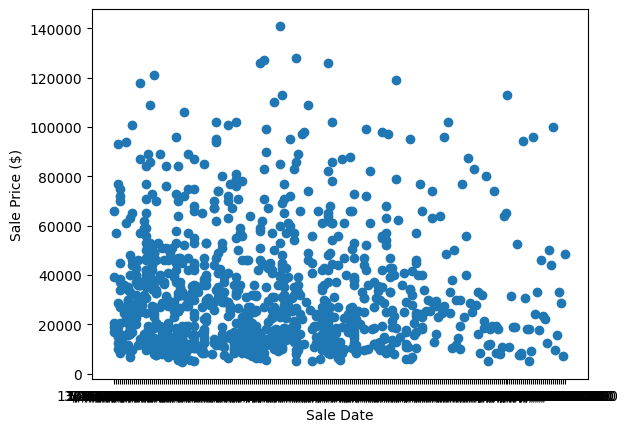

In [96]:
fig, ax = plt.subplots()
ax.scatter(x=df["saledate"][:1000],
          y=df["SalePrice"][:1000])
ax.set_xlabel("Sale Date")
ax.set_ylabel("Sale Price ($)")

<Axes: xlabel='Sale Price ($)', ylabel='Frequency'>

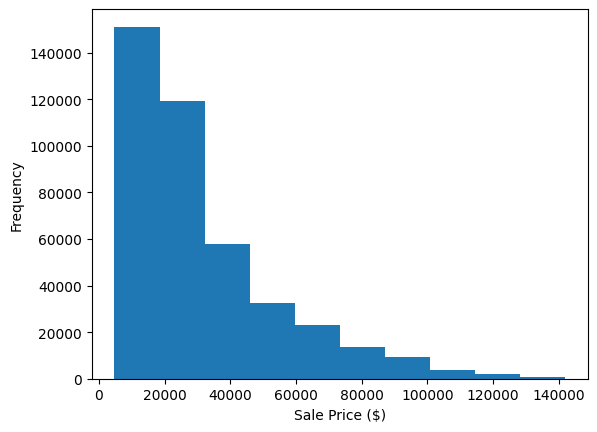

In [97]:
df.SalePrice.plot.hist(xlabel="Sale Price ($)")

In [98]:
df = pd.read_csv(filepath_or_buffer="../data/bluebook-for-bulldozers/TrainAndValid.csv",
                low_memory=False,
                parse_dates=["saledate"])

In [99]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412698 entries, 0 to 412697
Data columns (total 53 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   SalesID                   412698 non-null  int64         
 1   SalePrice                 412698 non-null  float64       
 2   MachineID                 412698 non-null  int64         
 3   ModelID                   412698 non-null  int64         
 4   datasource                412698 non-null  int64         
 5   auctioneerID              392562 non-null  float64       
 6   YearMade                  412698 non-null  int64         
 7   MachineHoursCurrentMeter  147504 non-null  float64       
 8   UsageBand                 73670 non-null   object        
 9   saledate                  412698 non-null  datetime64[ns]
 10  fiModelDesc               412698 non-null  object        
 11  fiBaseModel               412698 non-null  object        
 12  fi

In [100]:
df["saledate"][:10]

0   2006-11-16
1   2004-03-26
2   2004-02-26
3   2011-05-19
4   2009-07-23
5   2008-12-18
6   2004-08-26
7   2005-11-17
8   2009-08-27
9   2007-08-09
Name: saledate, dtype: datetime64[ns]

Text(0, 0.5, 'Sale Price ($)')

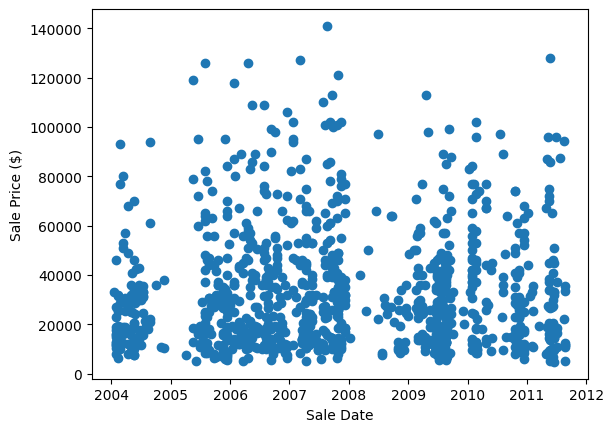

In [101]:
fig, ax = plt.subplots()
ax.scatter(x=df["saledate"][:1000],
          y=df["SalePrice"][:1000])
ax.set_xlabel("Sale Date")
ax.set_ylabel("Sale Price ($)")

In [102]:
df.sort_values(by=["saledate"], inplace=True, ascending=True)
df.saledate.head(10), df.saledate.tail(10)

(205615   1989-01-17
 274835   1989-01-31
 141296   1989-01-31
 212552   1989-01-31
 62755    1989-01-31
 54653    1989-01-31
 81383    1989-01-31
 204924   1989-01-31
 135376   1989-01-31
 113390   1989-01-31
 Name: saledate, dtype: datetime64[ns],
 409202   2012-04-28
 408976   2012-04-28
 411695   2012-04-28
 411319   2012-04-28
 408889   2012-04-28
 410879   2012-04-28
 412476   2012-04-28
 411927   2012-04-28
 407124   2012-04-28
 409203   2012-04-28
 Name: saledate, dtype: datetime64[ns])

In [103]:
df_tmp = df.copy()

In [104]:
df_tmp["saleYear"] = df_tmp.saledate.dt.year
df_tmp["saleMonth"] = df_tmp.saledate.dt.month
df_tmp["saleDay"] = df_tmp.saledate.dt.day
df_tmp["saleDayofweek"] = df_tmp.saledate.dt.dayofweek
df_tmp["saleDayofyear"] = df_tmp.saledate.dt.dayofyear

df_tmp.drop("saledate", axis=1, inplace=True)

In [105]:
# View newly created columns
df_tmp[["SalePrice", "saleYear", "saleMonth", "saleDay", "saleDayofweek", "saleDayofyear"]].head()

,SalePrice,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear
205615,9500.0,1989,1,17,1,17
274835,14000.0,1989,1,31,1,31
141296,50000.0,1989,1,31,1,31
212552,16000.0,1989,1,31,1,31
62755,22000.0,1989,1,31,1,31


In [106]:
df_tmp[["SalePrice", "saleYear", "saleMonth", "saleDay", "saleDayofweek", "saleDayofyear"]].shape

(412698, 6)

Text(0, 0.5, 'Sale Price ($)')

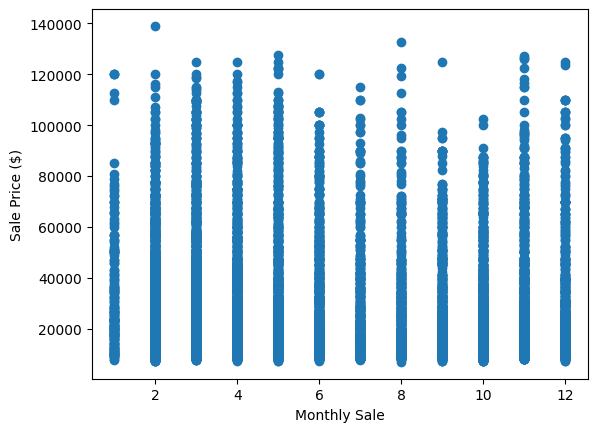

In [107]:
fig, ax = plt.subplots()
ax.scatter(x=df_tmp["saleMonth"][:10000],
          y=df_tmp["SalePrice"][:10000])
ax.set_xlabel("Monthly Sale")
ax.set_ylabel("Sale Price ($)")

Text(0, 0.5, 'Median Sale Price ($)')

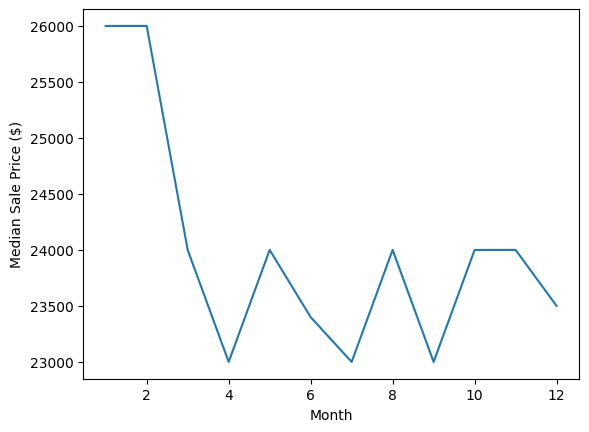

In [108]:
df_tmp.groupby(["saleMonth"])["SalePrice"].median().plot()
plt.xlabel("Month")
plt.ylabel("Median Sale Price ($)")

In [109]:
df_tmp.state.value_counts()[:10]

state
Florida        67320
Texas          53110
California     29761
Washington     16222
Georgia        14633
Maryland       13322
Mississippi    13240
Ohio           12369
Illinois       11540
Colorado       11529
Name: count, dtype: int64

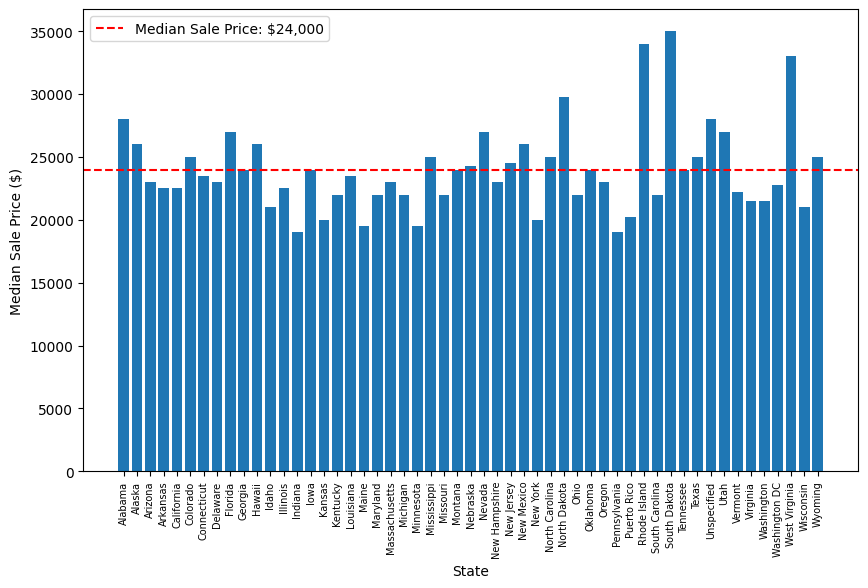

In [110]:
median_price_by_state = df_tmp.groupby(["state"])["SalePrice"].median()
median_sale_price = df_tmp["SalePrice"].median()

plt.figure(figsize=(10,6))
plt.bar(x=median_price_by_state.index,
       height=median_price_by_state.values)
plt.xlabel("State")
plt.ylabel("Median Sale Price ($)")
plt.xticks(rotation=90, fontsize=7)
plt.axhline(y=median_sale_price, color='red', linestyle='--', label=f"Median Sale Price: ${median_sale_price:,.0f}")
plt.legend()

In [111]:
df_tmp.head(10).isna()

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,...,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear
205615,False,False,False,False,False,False,False,True,True,False,...,False,False,False,True,True,False,False,False,False,False
274835,False,False,False,False,False,False,False,True,True,False,...,True,True,True,False,False,False,False,False,False,False
141296,False,False,False,False,False,False,False,True,True,False,...,False,False,False,True,True,False,False,False,False,False
212552,False,False,False,False,False,False,False,True,True,False,...,True,True,True,False,False,False,False,False,False,False
62755,False,False,False,False,False,False,False,True,True,False,...,False,False,False,True,True,False,False,False,False,False
54653,False,False,False,False,False,False,False,True,True,False,...,False,False,False,True,True,False,False,False,False,False
81383,False,False,False,False,False,False,False,True,True,False,...,True,True,True,False,False,False,False,False,False,False
204924,False,False,False,False,False,False,False,True,True,False,...,True,True,True,False,False,False,False,False,False,False
135376,False,False,False,False,False,False,False,True,True,False,...,False,False,False,True,True,False,False,False,False,False
113390,False,False,False,False,False,False,False,True,True,False,...,True,True,True,True,True,False,False,False,False,False


In [112]:
df_tmp.info()

<class 'pandas.core.frame.DataFrame'>
Index: 412698 entries, 205615 to 409203
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   SalesID                   412698 non-null  int64  
 1   SalePrice                 412698 non-null  float64
 2   MachineID                 412698 non-null  int64  
 3   ModelID                   412698 non-null  int64  
 4   datasource                412698 non-null  int64  
 5   auctioneerID              392562 non-null  float64
 6   YearMade                  412698 non-null  int64  
 7   MachineHoursCurrentMeter  147504 non-null  float64
 8   UsageBand                 73670 non-null   object 
 9   fiModelDesc               412698 non-null  object 
 10  fiBaseModel               412698 non-null  object 
 11  fiSecondaryDesc           271971 non-null  object 
 12  fiModelSeries             58667 non-null   object 
 13  fiModelDescriptor         74816 non-null   o

In [113]:
df_tmp.isna().sum()

SalesID                          0
SalePrice                        0
MachineID                        0
ModelID                          0
datasource                       0
auctioneerID                 20136
YearMade                         0
MachineHoursCurrentMeter    265194
UsageBand                   339028
fiModelDesc                      0
fiBaseModel                      0
fiSecondaryDesc             140727
fiModelSeries               354031
fiModelDescriptor           337882
ProductSize                 216605
fiProductClassDesc               0
state                            0
ProductGroup                     0
ProductGroupDesc                 0
Drive_System                305611
Enclosure                      334
Forks                       214983
Pad_Type                    331602
Ride_Control                259970
Stick                       331602
Transmission                224691
Turbocharged                331602
Blade_Extension             386715
Blade_Width         

In [114]:
df_tmp["UsageBand"].dtype, df_tmp['UsageBand'].name

(dtype('O'), 'UsageBand')

In [115]:
pd.api.types.is_object_dtype(df_tmp["UsageBand"])

True

In [116]:
pd.api.types.is_string_dtype(df_tmp["state"])

True

In [117]:
for label, content in df_tmp.items():
    if pd.api.types.is_object_dtype(content):
        df_tmp[label] = df_tmp[label].astype("category")

In [118]:
df_tmp.info()

<class 'pandas.core.frame.DataFrame'>
Index: 412698 entries, 205615 to 409203
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   SalesID                   412698 non-null  int64   
 1   SalePrice                 412698 non-null  float64 
 2   MachineID                 412698 non-null  int64   
 3   ModelID                   412698 non-null  int64   
 4   datasource                412698 non-null  int64   
 5   auctioneerID              392562 non-null  float64 
 6   YearMade                  412698 non-null  int64   
 7   MachineHoursCurrentMeter  147504 non-null  float64 
 8   UsageBand                 73670 non-null   category
 9   fiModelDesc               412698 non-null  category
 10  fiBaseModel               412698 non-null  category
 11  fiSecondaryDesc           271971 non-null  category
 12  fiModelSeries             58667 non-null   category
 13  fiModelDescriptor         748

In [119]:
df_tmp.state.dtype

CategoricalDtype(categories=['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California',
                  'Colorado', 'Connecticut', 'Delaware', 'Florida', 'Georgia',
                  'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas',
                  'Kentucky', 'Louisiana', 'Maine', 'Maryland',
                  'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi',
                  'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire',
                  'New Jersey', 'New Mexico', 'New York', 'North Carolina',
                  'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania',
                  'Puerto Rico', 'Rhode Island', 'South Carolina',
                  'South Dakota', 'Tennessee', 'Texas', 'Unspecified', 'Utah',
                  'Vermont', 'Virginia', 'Washington', 'Washington DC',
                  'West Virginia', 'Wisconsin', 'Wyoming'],
, ordered=False, categories_dtype=object)

In [120]:
df_tmp.UsageBand.dtype

CategoricalDtype(categories=['High', 'Low', 'Medium'], ordered=False, categories_dtype=object)

In [121]:
df_tmp.state.cat.categories

Index(['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado',
       'Connecticut', 'Delaware', 'Florida', 'Georgia', 'Hawaii', 'Idaho',
       'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana',
       'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota',
       'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada',
       'New Hampshire', 'New Jersey', 'New Mexico', 'New York',
       'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon',
       'Pennsylvania', 'Puerto Rico', 'Rhode Island', 'South Carolina',
       'South Dakota', 'Tennessee', 'Texas', 'Unspecified', 'Utah', 'Vermont',
       'Virginia', 'Washington', 'Washington DC', 'West Virginia', 'Wisconsin',
       'Wyoming'],
      dtype='object')

In [122]:
df_tmp.state.cat.codes

205615    43
274835     8
141296     8
212552     8
62755      8
          ..
410879     4
412476     4
411927     4
407124     4
409203     4
Length: 412698, dtype: int8

In [123]:
target_state_cat_no = 43
target_state_cat_val= df_tmp.state.cat.categories[target_state_cat_no]

print(f"[INFO] Target state categoty numbrt {target_state_cat_no} map to {target_state_cat_val}.")

[INFO] Target state categoty numbrt 43 map to Texas.


In [124]:
target_state_cat_no = 4
target_state_cat_val= df_tmp.state.cat.categories[target_state_cat_no]

print(f"[INFO] Target state categoty numbrt {target_state_cat_no} map to {target_state_cat_val}.")

[INFO] Target state categoty numbrt 4 map to California.


In [125]:
# Save preprocessed data to file
df_tmp.to_csv("../data/bluebook-for-bulldozers/TrainAndValid_object_values_as_categories.csv",
              index=False)

In [126]:
# Import preprocessed data to file
df_tmp = pd.read_csv("../data/bluebook-for-bulldozers/TrainAndValid_object_values_as_categories.csv",
                     low_memory=False)

df_tmp.head()

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,...,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear
0,1646770,9500.0,1126363,8434,132,18.0,1974,NaN,NaN,TD20,...,None or Unspecified,Straight,None or Unspecified,NaN,NaN,1989,1,17,1,17
1,1821514,14000.0,1194089,10150,132,99.0,1980,NaN,NaN,A66,...,NaN,NaN,NaN,Standard,Conventional,1989,1,31,1,31
2,1505138,50000.0,1473654,4139,132,99.0,1978,NaN,NaN,D7G,...,None or Unspecified,Straight,None or Unspecified,NaN,NaN,1989,1,31,1,31
3,1671174,16000.0,1327630,8591,132,99.0,1980,NaN,NaN,A62,...,NaN,NaN,NaN,Standard,Conventional,1989,1,31,1,31
4,1329056,22000.0,1336053,4089,132,99.0,1984,NaN,NaN,D3B,...,None or Unspecified,PAT,Lever,NaN,NaN,1989,1,31,1,31


In [127]:
df_tmp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412698 entries, 0 to 412697
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   SalesID                   412698 non-null  int64  
 1   SalePrice                 412698 non-null  float64
 2   MachineID                 412698 non-null  int64  
 3   ModelID                   412698 non-null  int64  
 4   datasource                412698 non-null  int64  
 5   auctioneerID              392562 non-null  float64
 6   YearMade                  412698 non-null  int64  
 7   MachineHoursCurrentMeter  147504 non-null  float64
 8   UsageBand                 73670 non-null   object 
 9   fiModelDesc               412698 non-null  object 
 10  fiBaseModel               412698 non-null  object 
 11  fiSecondaryDesc           271971 non-null  object 
 12  fiModelSeries             58667 non-null   object 
 13  fiModelDescriptor         74816 non-null   o

In [128]:
#Object types are back because of csv format

In [129]:
for label, content in df_tmp.items():
    if pd.api.types.is_object_dtype(content):
        df_tmp[label] = df_tmp[label].astype("category")

In [130]:
df_tmp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412698 entries, 0 to 412697
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   SalesID                   412698 non-null  int64   
 1   SalePrice                 412698 non-null  float64 
 2   MachineID                 412698 non-null  int64   
 3   ModelID                   412698 non-null  int64   
 4   datasource                412698 non-null  int64   
 5   auctioneerID              392562 non-null  float64 
 6   YearMade                  412698 non-null  int64   
 7   MachineHoursCurrentMeter  147504 non-null  float64 
 8   UsageBand                 73670 non-null   category
 9   fiModelDesc               412698 non-null  category
 10  fiBaseModel               412698 non-null  category
 11  fiSecondaryDesc           271971 non-null  category
 12  fiModelSeries             58667 non-null   category
 13  fiModelDescriptor         748

In [131]:
df_tmp.isna().sum().sort_values(ascending=False)[:20]

Blade_Width          386715
Engine_Horsepower    386715
Tip_Control          386715
Pushblock            386715
Blade_Extension      386715
Enclosure_Type       386715
Scarifier            386704
Hydraulics_Flow      367823
Grouser_Tracks       367823
Coupler_System       367724
fiModelSeries        354031
Steering_Controls    341176
Differential_Type    341134
UsageBand            339028
fiModelDescriptor    337882
Backhoe_Mounting     331986
Stick                331602
Turbocharged         331602
Pad_Type             331602
Blade_Type           330823
dtype: int64

In [132]:
df_tmp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 412698 entries, 0 to 412697
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   SalesID                   412698 non-null  int64   
 1   SalePrice                 412698 non-null  float64 
 2   MachineID                 412698 non-null  int64   
 3   ModelID                   412698 non-null  int64   
 4   datasource                412698 non-null  int64   
 5   auctioneerID              392562 non-null  float64 
 6   YearMade                  412698 non-null  int64   
 7   MachineHoursCurrentMeter  147504 non-null  float64 
 8   UsageBand                 73670 non-null   category
 9   fiModelDesc               412698 non-null  category
 10  fiBaseModel               412698 non-null  category
 11  fiSecondaryDesc           271971 non-null  category
 12  fiModelSeries             58667 non-null   category
 13  fiModelDescriptor         748

In [133]:
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if pd.isnull(content).sum():
            print(f"Column name: {label} has missing values: {True}")
        else:
            print(f"Column name: {label} has missing values: {False}")

Column name: SalesID has missing values: False
Column name: SalePrice has missing values: False
Column name: MachineID has missing values: False
Column name: ModelID has missing values: False
Column name: datasource has missing values: False
Column name: auctioneerID has missing values: True
Column name: YearMade has missing values: False
Column name: MachineHoursCurrentMeter has missing values: True
Column name: saleYear has missing values: False
Column name: saleMonth has missing values: False
Column name: saleDay has missing values: False
Column name: saleDayofweek has missing values: False
Column name: saleDayofyear has missing values: False


In [134]:
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if pd.isnull(content).sum():
            df_tmp[label+"_is_missing"] = pd.isnull(content).astype(int)
            df_tmp[label] = content.fillna(content.median())

In [135]:
df_tmp.columns

Index(['SalesID', 'SalePrice', 'MachineID', 'ModelID', 'datasource',
       'auctioneerID', 'YearMade', 'MachineHoursCurrentMeter', 'UsageBand',
       'fiModelDesc', 'fiBaseModel', 'fiSecondaryDesc', 'fiModelSeries',
       'fiModelDescriptor', 'ProductSize', 'fiProductClassDesc', 'state',
       'ProductGroup', 'ProductGroupDesc', 'Drive_System', 'Enclosure',
       'Forks', 'Pad_Type', 'Ride_Control', 'Stick', 'Transmission',
       'Turbocharged', 'Blade_Extension', 'Blade_Width', 'Enclosure_Type',
       'Engine_Horsepower', 'Hydraulics', 'Pushblock', 'Ripper', 'Scarifier',
       'Tip_Control', 'Tire_Size', 'Coupler', 'Coupler_System',
       'Grouser_Tracks', 'Hydraulics_Flow', 'Track_Type',
       'Undercarriage_Pad_Width', 'Stick_Length', 'Thumb', 'Pattern_Changer',
       'Grouser_Type', 'Backhoe_Mounting', 'Blade_Type', 'Travel_Controls',
       'Differential_Type', 'Steering_Controls', 'saleYear', 'saleMonth',
       'saleDay', 'saleDayofweek', 'saleDayofyear', 'auctioneerI

In [136]:
df_tmp[df_tmp["MachineHoursCurrentMeter_is_missing"]==1].sample(5)

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,...,Travel_Controls,Differential_Type,Steering_Controls,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear,auctioneerID_is_missing,MachineHoursCurrentMeter_is_missing
51509,1425173,80000.0,883421,4139,132,6.0,1989,0.0,NaN,D7G,...,None or Unspecified,NaN,NaN,1996,12,18,2,353,0,1
172030,1634261,19500.0,1479749,4604,132,8.0,1999,0.0,NaN,310E,...,NaN,NaN,NaN,2004,11,17,2,322,0,1
43216,1606170,15000.0,1281313,4781,132,4.0,1978,0.0,NaN,690B,...,NaN,NaN,NaN,1996,2,8,3,39,0,1
19350,1297716,29000.0,1531830,4124,132,1.0,1977,0.0,NaN,D6D,...,None or Unspecified,NaN,NaN,1992,12,8,1,343,0,1
27775,1518836,48000.0,1207258,1564,132,1.0,1986,0.0,NaN,D4HLGP,...,None or Unspecified,NaN,NaN,1994,3,17,3,76,0,1


In [137]:
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if pd.isnull(content).sum():
            print(f"Column name: {label} has missing values: {True}")
        else:
            print(f"Column name: {label} has missing values: {False}")

Column name: SalesID has missing values: False
Column name: SalePrice has missing values: False
Column name: MachineID has missing values: False
Column name: ModelID has missing values: False
Column name: datasource has missing values: False
Column name: auctioneerID has missing values: False
Column name: YearMade has missing values: False
Column name: MachineHoursCurrentMeter has missing values: False
Column name: saleYear has missing values: False
Column name: saleMonth has missing values: False
Column name: saleDay has missing values: False
Column name: saleDayofweek has missing values: False
Column name: saleDayofyear has missing values: False
Column name: auctioneerID_is_missing has missing values: False
Column name: MachineHoursCurrentMeter_is_missing has missing values: False


In [138]:
df_tmp.auctioneerID_is_missing.value_counts()

auctioneerID_is_missing
0    392562
1     20136
Name: count, dtype: int64

In [139]:
for label, content in df_tmp.items():
    if not pd.api.types.is_numeric_dtype(content):
        print(f"Column name: {label} | Column dtye: {df_tmp[label].dtype.name}")

Column name: UsageBand | Column dtye: category
Column name: fiModelDesc | Column dtye: category
Column name: fiBaseModel | Column dtye: category
Column name: fiSecondaryDesc | Column dtye: category
Column name: fiModelSeries | Column dtye: category
Column name: fiModelDescriptor | Column dtye: category
Column name: ProductSize | Column dtye: category
Column name: fiProductClassDesc | Column dtye: category
Column name: state | Column dtye: category
Column name: ProductGroup | Column dtye: category
Column name: ProductGroupDesc | Column dtye: category
Column name: Drive_System | Column dtye: category
Column name: Enclosure | Column dtye: category
Column name: Forks | Column dtye: category
Column name: Pad_Type | Column dtye: category
Column name: Ride_Control | Column dtye: category
Column name: Stick | Column dtye: category
Column name: Transmission | Column dtye: category
Column name: Turbocharged | Column dtye: category
Column name: Blade_Extension | Column dtye: category
Column name:

In [140]:
column_to_category_dict = {}
for label, content in df_tmp.items():
    if not pd.api.types.is_numeric_dtype(content):
        df_tmp[label+"_is_missing"] = pd.isnull(content).astype(int)
        content_categories = pd.Categorical(content)
        content_category_codes = content_categories.codes + 1
        column_to_category_dict[label] = dict(zip(content_category_codes, content_categories))
        df_tmp[label] = content_category_codes

In [141]:
df_tmp.sample(5)

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,...,Undercarriage_Pad_Width_is_missing,Stick_Length_is_missing,Thumb_is_missing,Pattern_Changer_is_missing,Grouser_Type_is_missing,Backhoe_Mounting_is_missing,Blade_Type_is_missing,Travel_Controls_is_missing,Differential_Type_is_missing,Steering_Controls_is_missing
270474,2238350,65000.0,52957,3824,136,2.0,1998,0.0,0,1746,...,1,1,1,1,1,1,1,1,0,0
29181,1725744,9000.0,1236314,8960,132,11.0,1000,0.0,0,1884,...,0,0,0,0,0,1,1,1,1,1
410964,6286203,30000.0,1799555,4605,149,1.0,2004,0.0,0,500,...,1,1,1,1,1,1,1,1,1,1
59337,1743180,21500.0,1215220,8988,132,9.0,1985,0.0,0,2045,...,1,1,1,1,1,0,0,0,1,1
178455,1580864,15500.0,1473814,4721,132,1.0,1977,0.0,0,1053,...,1,1,1,1,1,1,1,1,1,1


In [142]:
for key, value in sorted(column_to_category_dict["UsageBand"].items()):  
    print(f"{key} -> {value}")

0 -> nan
1 -> High
2 -> Low
3 -> Medium


In [143]:
 df_tmp["UsageBand"].dtype

dtype('int8')

In [144]:
 print(column_to_category_dict.keys())

dict_keys(['UsageBand', 'fiModelDesc', 'fiBaseModel', 'fiSecondaryDesc', 'fiModelSeries', 'fiModelDescriptor', 'ProductSize', 'fiProductClassDesc', 'state', 'ProductGroup', 'ProductGroupDesc', 'Drive_System', 'Enclosure', 'Forks', 'Pad_Type', 'Ride_Control', 'Stick', 'Transmission', 'Turbocharged', 'Blade_Extension', 'Blade_Width', 'Enclosure_Type', 'Engine_Horsepower', 'Hydraulics', 'Pushblock', 'Ripper', 'Scarifier', 'Tip_Control', 'Tire_Size', 'Coupler', 'Coupler_System', 'Grouser_Tracks', 'Hydraulics_Flow', 'Track_Type', 'Undercarriage_Pad_Width', 'Stick_Length', 'Thumb', 'Pattern_Changer', 'Grouser_Type', 'Backhoe_Mounting', 'Blade_Type', 'Travel_Controls', 'Differential_Type', 'Steering_Controls'])


In [145]:
for key, value in sorted(column_to_category_dict["state"].items()):
    print(f"{key} -> {value}")

1 -> Alabama
2 -> Alaska
3 -> Arizona
4 -> Arkansas
5 -> California
6 -> Colorado
7 -> Connecticut
8 -> Delaware
9 -> Florida
10 -> Georgia
11 -> Hawaii
12 -> Idaho
13 -> Illinois
14 -> Indiana
15 -> Iowa
16 -> Kansas
17 -> Kentucky
18 -> Louisiana
19 -> Maine
20 -> Maryland
21 -> Massachusetts
22 -> Michigan
23 -> Minnesota
24 -> Mississippi
25 -> Missouri
26 -> Montana
27 -> Nebraska
28 -> Nevada
29 -> New Hampshire
30 -> New Jersey
31 -> New Mexico
32 -> New York
33 -> North Carolina
34 -> North Dakota
35 -> Ohio
36 -> Oklahoma
37 -> Oregon
38 -> Pennsylvania
39 -> Puerto Rico
40 -> Rhode Island
41 -> South Carolina
42 -> South Dakota
43 -> Tennessee
44 -> Texas
45 -> Unspecified
46 -> Utah
47 -> Vermont
48 -> Virginia
49 -> Washington
50 -> Washington DC
51 -> West Virginia
52 -> Wisconsin
53 -> Wyoming


In [146]:
total_missing_values = df_tmp.isna().sum().sum()
if total_missing_values == 0:
    print(f"[INFO] Total missing values: {total_missing_values}.")
else:
    print(f"[INFO] Total missing vlaues: {total_missing_values} left.")

[INFO] Total missing values: 0.


In [147]:
# Save preprocessed data with object values as categories as well as missing values filled
df_tmp.to_parquet(path="../data/bluebook-for-bulldozers/TrainAndValid_object_values_as_categories_and_missing_values_filled.parquet",
                  engine="auto")

In [148]:
# Read in preprocessed dataset
df_tmp = pd.read_parquet(path="../data/bluebook-for-bulldozers/TrainAndValid_object_values_as_categories_and_missing_values_filled.parquet",
                         engine="auto")

In [149]:
total_missing_values = df_tmp.isna().sum().sum()
if total_missing_values == 0:
    print(f"[INFO] Total missing values: {total_missing_values}.")
else:
    print(f"[INFO] Total missing vlaues: {total_missing_values} left.")

[INFO] Total missing values: 0.


In [150]:
%%time

from sklearn.ensemble import RandomForestRegressor

df_tmp_sample_1k = df_tmp.sample(n=1000, random_state=42)
model = RandomForestRegressor(n_jobs=-1)
X_1k = df_tmp_sample_1k.drop("SalePrice", axis=1)
y_1k = df_tmp_sample_1k["SalePrice"]

model.fit(X=X_1k, y=y_1k)

CPU times: user 1.16 s, sys: 46.5 ms, total: 1.21 s
Wall time: 271 ms


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [151]:
model_1k_score = model.score(X=X_1k, y=y_1k)
print(f"[INFO] Model score on {len(df_tmp_sample_1k)} sample: {model_1k_score}")

[INFO] Model score on 1000 sample: 0.9553120579078757


In [152]:
%%time

X_all = df_tmp.drop("SalePrice", axis=1)
y_all = df_tmp["SalePrice"]

model.fit(X=X_all, y=y_all)

CPU times: user 11min 42s, sys: 6.15 s, total: 11min 48s
Wall time: 1min 39s


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [153]:
model_score = model.score(X=X_all, y=y_all)
print(f"[INFO] Model score on {len(df_tmp)} samples: {model_score}.")

[INFO] Model score on 412698 samples: 0.9875791344763932.


In [154]:
train_df = pd.read_csv(filepath_or_buffer="../data/bluebook-for-bulldozers/Train.csv",
                       parse_dates=["saledate"],
                       low_memory=False).sort_values(by="saledate", ascending=True)
valid_df = pd.read_csv(filepath_or_buffer="../data/bluebook-for-bulldozers/Valid.csv",
                       parse_dates=["saledate"])
valid_solution = pd.read_csv(filepath_or_buffer="../data/bluebook-for-bulldozers/ValidSolution.csv")
valid_df["SalePrice"] = valid_df["SalesID"].map(valid_solution.set_index("SalesID")["SalePrice"])
valid_df = valid_df.sort_values("saledate", ascending=True).reset_index(drop=True)

print(f"[INFO] Number of samples in training DataFrame: {len(train_df)}")
print(f"[INFO] Number of samples in validation DataFrame: {len(valid_df)}")

[INFO] Number of samples in training DataFrame: 401125
[INFO] Number of samples in validation DataFrame: 11573


In [155]:
train_df.sample(5)

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,saledate,...,Undercarriage_Pad_Width,Stick_Length,Thumb,Pattern_Changer,Grouser_Type,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls
85561,1388283,36000,490620,3538,132,1.0,2000,NaN,NaN,2004-03-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79057,1373274,9000,1485360,6979,132,1.0,1972,NaN,NaN,2004-06-23,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
145030,1513735,54000,1158672,3371,132,1.0,1984,NaN,NaN,2002-04-11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7120,1163206,53000,168048,1597,121,3.0,1998,3944.0,Medium,2006-12-07,...,NaN,NaN,NaN,NaN,NaN,None or Unspecified,VPAT,Finger Tip,NaN,NaN
265997,1802424,13500,1375825,9508,132,1.0,1998,NaN,NaN,2005-02-15,...,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN,NaN


In [156]:
valid_df.sample(5)

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,saledate,fiModelDesc,...,Stick_Length,Thumb,Pattern_Changer,Grouser_Type,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls,SalePrice
10261,4375295,2308152,17309,172,1,2006,1958.0,Medium,2012-04-10,S130,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12000.0
9114,6319647,1824983,18139,149,1,2005,NaN,NaN,2012-03-29,EC160BLC,...,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN,NaN,66000.0
2590,4354023,2280816,16251,172,1,1997,5855.0,Low,2012-02-12,SK150LC,...,None or Unspecified,Hydraulic,None or Unspecified,Triple,NaN,NaN,NaN,NaN,NaN,24000.0
11333,6291768,1262274,11594,149,99,1997,NaN,NaN,2012-04-25,EX200-3,...,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN,NaN,26000.0
9211,6304261,818895,28718,149,1,2006,NaN,NaN,2012-03-29,SK10205N,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8000.0


In [157]:
def add_datetime_features_to_df(df, date_column="saledate"):
    df["saleYear"] = df[date_column].dt.year
    df["saleMonth"] = df[date_column].dt.month
    df["saleDay"] = df[date_column].dt.day
    df["saleDayofweek"] = df[date_column].dt.dayofweek
    df["saleDayofyear"] = df[date_column].dt.dayofyear

    df.drop("saledate", axis=1, inplace=True)
    return df

train_df = add_datetime_features_to_df(df=train_df)
valid_df = add_datetime_features_to_df(df=valid_df)

In [158]:
train_df.iloc[:, -5:].sample(5)

,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear
23031,2011,10,20,3,293
209405,2007,2,13,1,44
165971,2004,6,4,4,156
106469,1994,10,19,2,292
333815,2008,2,19,1,50


In [159]:
# Split training data into features and labels
X_train = train_df.drop("SalePrice", axis=1)
y_train = train_df["SalePrice"]

# Split validation data into features and labels
X_valid = valid_df.drop("SalePrice", axis=1)
y_valid = valid_df["SalePrice"]

model = RandomForestRegressor(n_jobs=-1)

In [174]:
numerical_features = [
    label for label, content in X_train.items()
    if pd.api.types.is_numeric_dtype(content)
]

categorical_features = [
    label for label, content in X_train.items()
    if pd.api.types.is_object_dtype(content)
    or pd.api.types.is_categorical_dtype(content)
]

print(f"[INFO] Numeric features: {numerical_features}")
print(f"[INFO] Categorical features: {categorical_features[:10]}...")
print(f"[INFO] Total categorical features: {len(categorical_features)}")

[INFO] Numeric features: ['SalesID', 'MachineID', 'ModelID', 'datasource', 'auctioneerID', 'YearMade', 'MachineHoursCurrentMeter', 'saleYear', 'saleMonth', 'saleDay', 'saleDayofweek', 'saleDayofyear']
[INFO] Categorical features: ['UsageBand', 'fiModelDesc', 'fiBaseModel', 'fiSecondaryDesc', 'fiModelSeries', 'fiModelDescriptor', 'ProductSize', 'fiProductClassDesc', 'state', 'ProductGroup']...
[INFO] Total categorical features: 44


/var/folders/0t/tlg8p4n91y1g2zyg12tmx_n00000gn/T/ipykernel_92180/2419836788.py:9: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  or pd.api.types.is_categorical_dtype(content)


In [175]:
from sklearn.preprocessing import OrdinalEncoder

# 1. Create an ordinal encoder (turns category items into numeric representation)
ordinal_encoder = OrdinalEncoder(categories="auto",
                                 handle_unknown="use_encoded_value",
                                 unknown_value=np.nan,
                                 encoded_missing_value=np.nan) # treat unknown categories as np.nan (or None)

# 2. Fit and transform the categorical columns of X_train
X_train_preprocessed = X_train.copy() # make copies of the oringal DataFrames so we can keep the original values in tact and view them later
X_train_preprocessed[categorical_features] = ordinal_encoder.fit_transform(X_train_preprocessed[categorical_features].astype(str)) # OrdinalEncoder expects all values as the same type (e.g. string or numeric only)

# 3. Transform the categorical columns of X_valid 
X_valid_preprocessed = X_valid.copy()
X_valid_preprocessed[categorical_features] = ordinal_encoder.transform(X_valid_preprocessed[categorical_features].astype(str)) # only use `transform` on the validation data

In [176]:
X_train.head(5)

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,fiBaseModel,...,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear
205615,1646770,1126363,8434,132,18.0,1974,NaN,NaN,TD20,TD20,...,None or Unspecified,Straight,None or Unspecified,NaN,NaN,1989,1,17,1,17
92803,1404019,1169900,7110,132,99.0,1986,NaN,NaN,416,416,...,NaN,NaN,NaN,NaN,NaN,1989,1,31,1,31
98346,1415646,1262088,3357,132,99.0,1975,NaN,NaN,12G,12,...,NaN,NaN,NaN,NaN,NaN,1989,1,31,1,31
169297,1596358,1433229,8247,132,99.0,1978,NaN,NaN,644,644,...,NaN,NaN,NaN,Standard,Conventional,1989,1,31,1,31
274835,1821514,1194089,10150,132,99.0,1980,NaN,NaN,A66,A66,...,NaN,NaN,NaN,Standard,Conventional,1989,1,31,1,31


In [177]:
X_train_preprocessed.head(5)

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,fiBaseModel,...,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear
205615,1646770,1126363,8434,132,18.0,1974,NaN,3.0,4536.0,1734.0,...,0.0,7.0,5.0,4.0,5.0,1989,1,17,1,17
92803,1404019,1169900,7110,132,99.0,1986,NaN,3.0,734.0,242.0,...,2.0,10.0,7.0,4.0,5.0,1989,1,31,1,31
98346,1415646,1262088,3357,132,99.0,1975,NaN,3.0,81.0,18.0,...,2.0,10.0,7.0,4.0,5.0,1989,1,31,1,31
169297,1596358,1433229,8247,132,99.0,1978,NaN,3.0,1157.0,348.0,...,2.0,10.0,7.0,3.0,1.0,1989,1,31,1,31
274835,1821514,1194089,10150,132,99.0,1980,NaN,3.0,1799.0,556.0,...,2.0,10.0,7.0,3.0,1.0,1989,1,31,1,31


In [178]:
X_train[categorical_features].isna().sum().sort_values(ascending=False)[:10]

Engine_Horsepower    375906
Blade_Extension      375906
Tip_Control          375906
Pushblock            375906
Enclosure_Type       375906
Blade_Width          375906
Scarifier            375895
Hydraulics_Flow      357763
Grouser_Tracks       357763
Coupler_System       357667
dtype: int64

In [179]:
X_train_preprocessed[categorical_features].isna().sum().sort_values(ascending=False)[:10]

UsageBand         0
fiModelDesc       0
Pushblock         0
Ripper            0
Scarifier         0
Tip_Control       0
Tire_Size         0
Coupler           0
Coupler_System    0
Grouser_Tracks    0
dtype: int64

In [180]:
ordinal_encoder.categories_[:3]

[array(['High', 'Low', 'Medium', 'nan'], dtype=object),
 array(['100C', '104', '1066', ..., 'ZX800LC', 'ZX80LCK', 'ZX850H'],
       dtype=object),
 array(['10', '100', '104', ..., 'ZX80', 'ZX800', 'ZX850'], dtype=object)]

In [181]:
print("Categorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Categorical features: ['UsageBand', 'fiModelDesc', 'fiBaseModel', 'fiSecondaryDesc', 'fiModelSeries', 'fiModelDescriptor', 'ProductSize', 'fiProductClassDesc', 'state', 'ProductGroup', 'ProductGroupDesc', 'Drive_System', 'Enclosure', 'Forks', 'Pad_Type', 'Ride_Control', 'Stick', 'Transmission', 'Turbocharged', 'Blade_Extension', 'Blade_Width', 'Enclosure_Type', 'Engine_Horsepower', 'Hydraulics', 'Pushblock', 'Ripper', 'Scarifier', 'Tip_Control', 'Tire_Size', 'Coupler', 'Coupler_System', 'Grouser_Tracks', 'Hydraulics_Flow', 'Track_Type', 'Undercarriage_Pad_Width', 'Stick_Length', 'Thumb', 'Pattern_Changer', 'Grouser_Type', 'Backhoe_Mounting', 'Blade_Type', 'Travel_Controls', 'Differential_Type', 'Steering_Controls']
Number of categorical features: 44


In [182]:
column_to_category_mapping = {}
for column_name, category_values in zip(categorical_features, ordinal_encoder.categories_):
    int_to_category = {i: category for i, category in enumerate(category_values)}
    column_to_category_mapping[column_name] = int_to_category
column_to_category_mapping["UsageBand"]

{0: 'High', 1: 'Low', 2: 'Medium', 3: 'nan'}

In [185]:
%%time
model.fit(X=X_train_preprocessed,
          y=y_train)

CPU times: user 9min 57s, sys: 4.01 s, total: 10min 1s
Wall time: 1min 23s


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [186]:
%%time
model.score(X=X_valid_preprocessed,
          y=y_valid)

CPU times: user 711 ms, sys: 1.05 s, total: 1.76 s
Wall time: 637 ms


0.8704329638108896

In [188]:
%%time
model.score(X=X_train_preprocessed,
          y=y_train)

CPU times: user 15.7 s, sys: 1.26 s, total: 17 s
Wall time: 2.85 s


0.9873118704235502

In [189]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_log_error
def show_scores(model,
               train_features=X_train_preprocessed,
               train_labels=y_train,
               valid_features=X_valid_preprocessed,
               valid_labels=y_valid):
    train_preds = model.predict(X=train_features)
    valid_preds = model.predict(X=valid_features)

    scores = {"Train MAE": mean_absolute_error(y_true=train_labels, y_pred=train_preds),
             "Valid MAE": mean_absolute_error(y_true=valid_labels, y_pred=valid_preds),
             "Train RMSLE": root_mean_squared_log_error(y_true=train_labels, y_pred=train_preds),
             "Valid RMSLE": root_mean_squared_log_error(y_true=valid_labels, y_pred=valid_preds),
             "Train R^2": model.score(X=train_features, y=train_labels),
             "Valid R^2": model.score(X=valid_features, y=valid_labels)}

    return scores

In [190]:
model_scores = show_scores(model=model)

In [191]:
model_scores

{'Train MAE': 1593.866431604295,
 'Valid MAE': 6173.199027045709,
 'Train RMSLE': 0.08532931830576197,
 'Valid RMSLE': 0.25823282860242003,
 'Train R^2': 0.9873118704235502,
 'Valid R^2': 0.8704329638108896}

In [192]:
model = RandomForestRegressor(n_estimators=100, n_jobs=-1, max_samples=10000)
model.fit(X_train_preprocessed, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [193]:
# Get evaluation metrics from reduced sample model
base_model_scores = show_scores(model=model)
base_model_scores

{'Train MAE': 5599.977362883555,
 'Valid MAE': 7151.295598087502,
 'Train RMSLE': 0.26051130939910616,
 'Valid RMSLE': 0.2938416596434679,
 'Train R^2': 0.8586326823822846,
 'Valid R^2': 0.8299131483332557}

In [194]:
%%time

from sklearn.model_selection import RandomizedSearchCV

rf_grid = {"n_estimators": np.arange(10, 200, 10),
          "max_depth": [None, 10, 20],
          "min_samples_split": np.arange(2, 10, 1),
          "min_samples_leaf": np.arange(1, 10, 1),
          "max_features": [0.5, 1.0, "sqrt"],
          "max_samples": [10000]}
rs_model = RandomizedSearchCV(estimator=RandomForestRegressor(),
                             param_distributions=rf_grid,
                             n_iter=20,
                             cv=3,
                             verbose=3)
rs_model.fit(X_train_preprocessed, y_train)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV 1/3] END max_depth=10, max_features=0.5, max_samples=10000, min_samples_leaf=4, min_samples_split=7, n_estimators=40;, score=0.522 total time=   2.2s
[CV 2/3] END max_depth=10, max_features=0.5, max_samples=10000, min_samples_leaf=4, min_samples_split=7, n_estimators=40;, score=0.716 total time=   2.0s
[CV 3/3] END max_depth=10, max_features=0.5, max_samples=10000, min_samples_leaf=4, min_samples_split=7, n_estimators=40;, score=0.626 total time=   2.1s
[CV 1/3] END max_depth=None, max_features=1.0, max_samples=10000, min_samples_leaf=5, min_samples_split=6, n_estimators=180;, score=0.539 total time=  19.2s
[CV 2/3] END max_depth=None, max_features=1.0, max_samples=10000, min_samples_leaf=5, min_samples_split=6, n_estimators=180;, score=0.753 total time=  19.3s
[CV 3/3] END max_depth=None, max_features=1.0, max_samples=10000, min_samples_leaf=5, min_samples_split=6, n_estimators=180;, score=0.617 total time=  18.6s
[CV 1/

,estimator,RandomForestRegressor()
,param_distributions,"{'max_depth': [None, 10, ...], 'max_features': [0.5, 1.0, ...], 'max_samples': [10000], 'min_samples_leaf': array([1, 2, ..., 6, 7, 8, 9]), ...}"
,n_iter,20
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [195]:
rs_model.best_params_

{'n_estimators': 150,
 'min_samples_split': 9,
 'min_samples_leaf': 2,
 'max_samples': 10000,
 'max_features': 0.5,
 'max_depth': 20}

In [196]:
rs_model_scores = show_scores(rs_model)
rs_model_scores

{'Train MAE': 5882.3826548503675,
 'Valid MAE': 7308.134146001348,
 'Train RMSLE': 0.27003625594006825,
 'Valid RMSLE': 0.30003795374642867,
 'Train R^2': 0.8457173972038341,
 'Valid R^2': 0.8254171022520688}

In [197]:
ideal_model = RandomForestRegressor(n_estimators=90,
                                    max_depth=None,
                                    min_samples_leaf=1,
                                    min_samples_split=5,
                                    max_features=0.5,
                                    n_jobs=-1,
                                    max_samples=None)

# Fit a model to the preprocessed data
ideal_model.fit(X=X_train_preprocessed, 
                y=y_train)

,n_estimators,90
,criterion,'squared_error'
,max_depth,None
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,0.5
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [198]:
%%time

# Evaluate ideal model
ideal_model_scores = show_scores(model=ideal_model)
ideal_model_scores

CPU times: user 24.4 s, sys: 1.18 s, total: 25.6 s
Wall time: 4.32 s


{'Train MAE': 1958.586544163679,
 'Valid MAE': 5969.668118992214,
 'Train RMSLE': 0.10226278446840412,
 'Valid RMSLE': 0.24679017484786767,
 'Train R^2': 0.9809993991349892,
 'Valid R^2': 0.8813292881907079}

In [200]:
fast_model = RandomForestRegressor(n_estimators=45,
                                  max_depth=None,
                                  min_samples_leaf=1,
                                  min_samples_split=5,
                                  max_features=0.5,
                                  n_jobs=-1,
                                  max_samples=None)
fast_model.fit(X_train_preprocessed, y_train)

fast_model_scores = show_scores(model=fast_model)
fast_model_scores

{'Train MAE': 1992.064020130215,
 'Valid MAE': 6006.8227085764975,
 'Train RMSLE': 0.10396741456733596,
 'Valid RMSLE': 0.24965090809780469,
 'Train R^2': 0.9802058396698248,
 'Valid R^2': 0.8809339874377743}

In [201]:
base_model_scores["model_name"] = "default_model"
rs_model_scores["model_name"] = "random_search_model"
ideal_model_scores["model_name"] = "ideal_model"
fast_model_scores["model_name"] = "fast_model"

all_model_scores = [base_model_scores,
                   rs_model_scores,
                   ideal_model_scores,
                   fast_model_scores]

model_comparison_df = pd.DataFrame(all_model_scores).sort_values(by="Valid RMSLE", ascending=False)
model_comparison_df.head(10)

,Train MAE,Valid MAE,Train RMSLE,Valid RMSLE,Train R^2,Valid R^2,model_name
1,5882.382655,7308.134146,0.270036,0.300038,0.845717,0.825417,random_search_model
0,5599.977363,7151.295598,0.260511,0.293842,0.858633,0.829913,default_model
3,1992.064020,6006.822709,0.103967,0.249651,0.980206,0.880934,fast_model
2,1958.586544,5969.668119,0.102263,0.246790,0.980999,0.881329,ideal_model


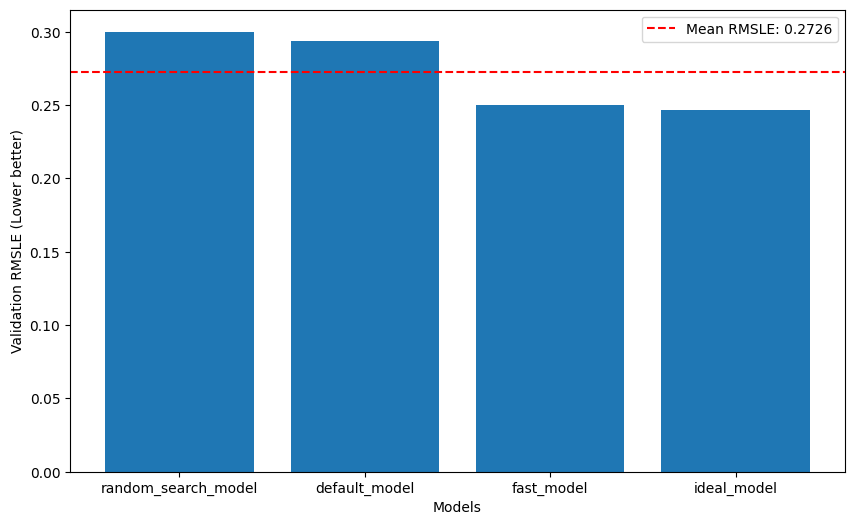

In [205]:
mean_rmsle_score = model_comparison_df["Valid RMSLE"].mean()
plt.figure(figsize=(10,6))
plt.bar(x=model_comparison_df["model_name"],
       height=model_comparison_df["Valid RMSLE"].values)
plt.xlabel("Models")
plt.ylabel("Validation RMSLE (Lower better)")
plt.xticks(rotation=0, fontsize=10)
plt.axhline(y=mean_rmsle_score,
           color="red",
           linestyle="--",
           label=f"Mean RMSLE: {mean_rmsle_score:.4f}")
plt.legend()

In [213]:
import joblib

bulldozer_price_prediction_model_name = "randomforest_regressor_best_RMSLE.pkl"

# Save model to file
joblib.dump(value=ideal_model, 
            filename=bulldozer_price_prediction_model_name)

['randomforest_regressor_best_RMSLE.pkl']

In [214]:
# Load the best model
best_model = joblib.load(filename=bulldozer_price_prediction_model_name)
best_model

,n_estimators,90
,criterion,'squared_error'
,max_depth,None
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,0.5
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [208]:
test_df = pd.read_csv(filepath_or_buffer="../data/bluebook-for-bulldozers/Test.csv",
                      parse_dates=["saledate"])
test_df.head()

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,saledate,fiModelDesc,...,Undercarriage_Pad_Width,Stick_Length,Thumb,Pattern_Changer,Grouser_Type,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls
0,1227829,1006309,3168,121,3,1999,3688.0,Low,2012-05-03,580G,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1227844,1022817,7271,121,3,1000,28555.0,High,2012-05-10,936,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
2,1227847,1031560,22805,121,3,2004,6038.0,Medium,2012-05-10,EC210BLC,...,None or Unspecified,"9' 6""",Manual,None or Unspecified,Double,NaN,NaN,NaN,NaN,NaN
3,1227848,56204,1269,121,3,2006,8940.0,High,2012-05-10,330CL,...,None or Unspecified,None or Unspecified,Manual,Yes,Triple,NaN,NaN,NaN,NaN,NaN
4,1227863,1053887,22312,121,3,2005,2286.0,Low,2012-05-10,650K,...,NaN,NaN,NaN,NaN,NaN,None or Unspecified,PAT,None or Unspecified,NaN,NaN


In [209]:
# Make a function to add date columns
def add_datetime_features_to_df(df, date_column="saledate"):
    # Add datetime parameters for saledate
    df["saleYear"] = df[date_column].dt.year
    df["saleMonth"] = df[date_column].dt.month
    df["saleDay"] = df[date_column].dt.day
    df["saleDayofweek"] = df[date_column].dt.dayofweek
    df["saleDayofyear"] = df[date_column].dt.dayofyear

    # Drop original saledate column
    df.drop("saledate", axis=1, inplace=True)

    return df

# Preprocess test_df to have same columns as train_df (add the datetime features)
test_df = add_datetime_features_to_df(df=test_df)
test_df.head()

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,fiBaseModel,...,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear
0,1227829,1006309,3168,121,3,1999,3688.0,Low,580G,580,...,NaN,NaN,NaN,NaN,NaN,2012,5,3,3,124
1,1227844,1022817,7271,121,3,1000,28555.0,High,936,936,...,NaN,NaN,NaN,Standard,Conventional,2012,5,10,3,131
2,1227847,1031560,22805,121,3,2004,6038.0,Medium,EC210BLC,EC210,...,NaN,NaN,NaN,NaN,NaN,2012,5,10,3,131
3,1227848,56204,1269,121,3,2006,8940.0,High,330CL,330,...,NaN,NaN,NaN,NaN,NaN,2012,5,10,3,131
4,1227863,1053887,22312,121,3,2005,2286.0,Low,650K,650,...,None or Unspecified,PAT,None or Unspecified,NaN,NaN,2012,5,10,3,131


In [210]:
test_df_preprocessed = test_df.copy()
test_df_preprocessed[categorical_features] = ordinal_encoder.transform(test_df_preprocessed[categorical_features].astype(str))
test_df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12457 entries, 0 to 12456
Data columns (total 56 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   SalesID                   12457 non-null  int64  
 1   MachineID                 12457 non-null  int64  
 2   ModelID                   12457 non-null  int64  
 3   datasource                12457 non-null  int64  
 4   auctioneerID              12457 non-null  int64  
 5   YearMade                  12457 non-null  int64  
 6   MachineHoursCurrentMeter  2129 non-null   float64
 7   UsageBand                 12457 non-null  float64
 8   fiModelDesc               12349 non-null  float64
 9   fiBaseModel               12431 non-null  float64
 10  fiSecondaryDesc           12449 non-null  float64
 11  fiModelSeries             12456 non-null  float64
 12  fiModelDescriptor         12452 non-null  float64
 13  ProductSize               12457 non-null  float64
 14  fiProd

In [217]:
test_preds = best_model.predict(test_df_preprocessed)
test_preds[:10]

array([15157.57892416, 31955.77160494, 49073.69708995, 96424.46428571,
       26547.32543691, 29689.83686067, 25959.30996473, 19888.19664903,
       17000.09832451, 30422.15207632])

In [218]:
pred_df = pd.DataFrame()
pred_df["SalesID"] = test_df["SalesID"]
pred_df["SalePrice"] = test_preds
pred_df.head(10)

,SalesID,SalePrice
0,1227829,15157.578924
1,1227844,31955.771605
2,1227847,49073.697090
3,1227848,96424.464286
4,1227863,26547.325437
5,1227870,29689.836861
6,1227871,25959.309965
7,1227879,19888.196649
8,1227880,17000.098325
9,1227881,30422.152076


In [219]:
# Find feature importance of our best model
best_model_feature_importances = best_model.feature_importances_
best_model_feature_importances

array([3.56943062e-02, 2.84737316e-02, 5.87819407e-02, 1.81204007e-03,
       5.26135983e-03, 1.90798366e-01, 6.75919911e-03, 1.41689405e-03,
       5.02908641e-02, 4.48666958e-02, 3.96967371e-02, 4.64735744e-03,
       2.76841955e-02, 1.55095065e-01, 4.71496811e-02, 8.31417061e-03,
       6.25053139e-03, 4.46811075e-03, 1.38029650e-03, 7.36889628e-02,
       7.27383561e-04, 1.37147859e-03, 2.05428767e-03, 6.06534055e-04,
       1.31737334e-03, 1.33581965e-04, 3.80769158e-03, 1.72251718e-03,
       5.73420265e-03, 3.32591464e-03, 3.13319301e-03, 4.93270235e-03,
       6.81593929e-03, 8.41609883e-04, 3.52871295e-03, 9.45181389e-03,
       1.80351664e-03, 1.99622588e-02, 8.01419700e-03, 8.10320706e-03,
       2.13560138e-03, 1.51690195e-03, 1.66748555e-03, 9.42246093e-04,
       6.76716530e-04, 8.14864690e-04, 6.93320700e-04, 2.99598514e-03,
       3.56327792e-03, 5.42909104e-04, 4.71096986e-04, 7.28848531e-02,
       5.44641343e-03, 8.54723916e-03, 4.43140731e-03, 1.27510598e-02])

In [220]:
print(f"[INFO] Number of feature importance values: {best_model_feature_importances.shape[0]}") 
print(f"[INFO] Number of features in training dataset: {X_train_preprocessed.shape[1]}")

[INFO] Number of feature importance values: 56
[INFO] Number of features in training dataset: 56


In [222]:
column_names = test_df.columns
feature_importance_df = pd.DataFrame({"Feature names": column_names,
                                     "feature_importance": best_model_feature_importances}).sort_values(by="feature_importance", ascending=False)
feature_importance_df.head(10)

,Feature names,feature_importance
5,YearMade,0.190798
13,ProductSize,0.155095
19,Enclosure,0.073689
51,saleYear,0.072885
2,ModelID,0.058782
8,fiModelDesc,0.050291
14,fiProductClassDesc,0.047150
9,fiBaseModel,0.044867
10,fiSecondaryDesc,0.039697
0,SalesID,0.035694


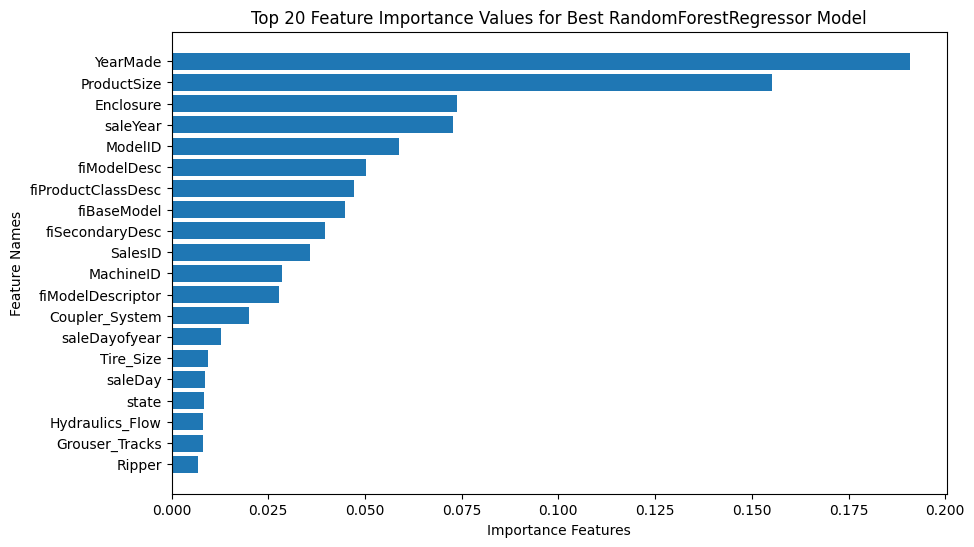

In [225]:
top_n = 20
plt.figure(figsize=(10,6))
plt.barh(y=feature_importance_df["Feature names"][:top_n],
        width=feature_importance_df["feature_importance"][:top_n])
plt.title(f"Top {top_n} Feature Importance Values for Best RandomForestRegressor Model")
plt.xlabel("Importance Features")
plt.ylabel("Feature Names")
plt.gca().invert_yaxis()